In [1]:
import os
import hydra
from omegaconf import OmegaConf, DictConfig
from rl4co.utils.ops import unbatchify, batchify, gather_by_index

import torch
import lightning as L
from lightning.pytorch.loggers import WandbLogger
from lightning.pytorch.callbacks import ModelCheckpoint

from rl4co.utils.trainer import RL4COTrainer
from rl4co.envs import get_env

from models.zoo.icam.model import ICAM
from models.zoo.udc.model import UDC

cfg = OmegaConf.load("./configs/udc.yaml")

L.seed_everything(cfg.get("seed", 1234))

model_r_params_dict = OmegaConf.to_container(cfg.model_r, resolve=True)

env_d = get_env(**cfg.env_d)
env_r = get_env(**cfg.env_r)

model_d = ICAM(
    env = env_d,
    **cfg.model_d,
)
model_r = ICAM(
    env = env_r,
    **model_r_params_dict,
)

model = UDC(
    model_d=model_d,
    model_r=model_r,
    **cfg.model,
)

if cfg.ckpt_path:
    ckpt_state_dict = torch.load(cfg.ckpt_path)['state_dict']
    model.load_state_dict(ckpt_state_dict)

/home/cpz/anaconda3/envs/rl4co/lib/python3.12/site-packages/torchrl/data/replay_buffers/samplers.py:37: UserWarning: Failed to import torchrl C++ binaries. Some modules (eg, prioritized replay buffers) may not work with your installation. If you installed TorchRL from PyPI, please report the bug on TorchRL github. If you installed TorchRL locally and/or in development mode, check that you have all the required compiling packages.
  warnings.warn(EXTENSION_WARNING)
/home/cpz/anaconda3/envs/rl4co/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/cpz/anaconda3/envs/rl4co/lib/python3.12/site-packages/torch/jit/frontend.py:1209: DeprecationWarning: ast.Str is deprecated and will be removed in Python 3.14; use ast.Constant instead
  elif isinstance(value, ast.Str):
/home/cpz/anaconda3/envs/rl4co/lib/pytho

Problem 1 | Cost: 16.728
Problem 2 | Cost: 16.840
Problem 3 | Cost: 16.828


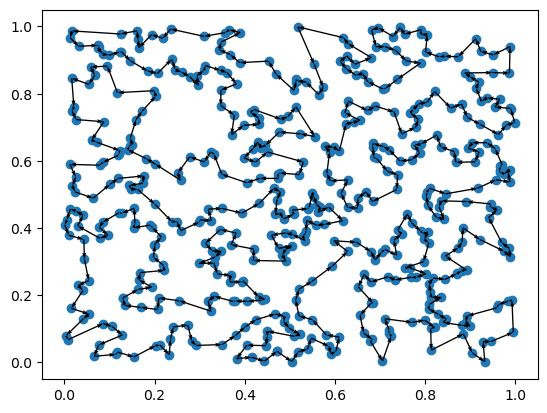

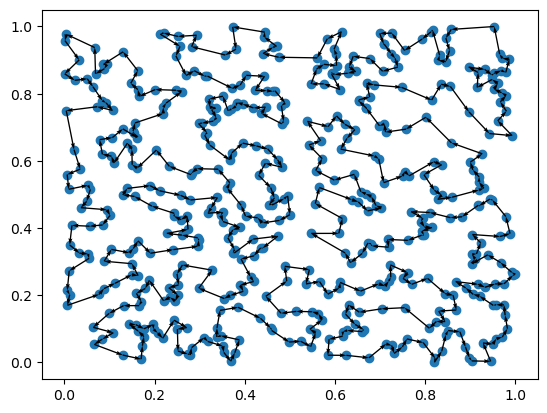

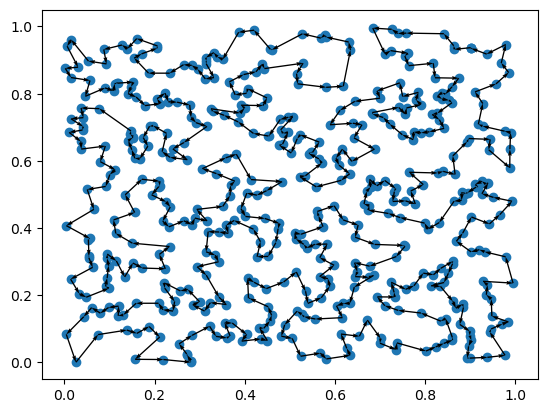

In [4]:
device = "cpu"
n_instances = 3
num_starts = 50
env = env_d
td_init = env.reset(batch_size=[n_instances]).to(device)
model = model.to(device)

out = model.infer(td_init.clone(), phase_d="test", phase_r="test", ns_d=num_starts, ns_r=1)
actions = out['actions'].cpu().detach()
rewards = out['reward'].cpu().detach()

max_rewards, max_idxs = rewards.max(dim=1)
best_actions = gather_by_index(actions, max_idxs, dim=1)

for i in range(3):
    print(f"Problem {i+1} | Cost: {-max_rewards[i]:.3f}")
    env.render(td_init[i], best_actions[i])

Problem 1 | Improved Cost: 16.717
Problem 2 | Improved Cost: 16.793
Problem 3 | Improved Cost: 16.809


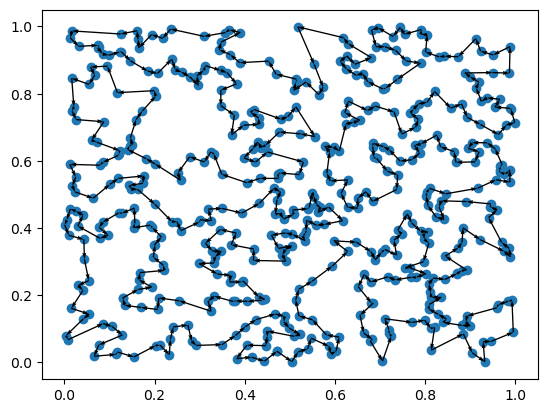

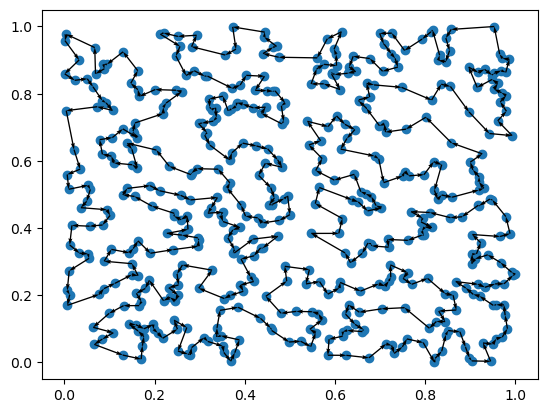

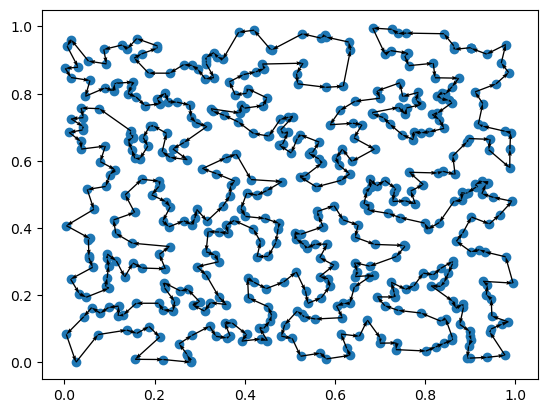

In [5]:
improved_actions = env.local_search(td_init, best_actions)
improved_rewards = env.get_reward(td_init, improved_actions)

for i in range(3):
    print(f"Problem {i+1} | Improved Cost: {-improved_rewards[i]:.3f}")
    env.render(td_init[i], improved_actions[i])